# Orbital foundations: one spacecraft around the Earth

A rendezvous mission is, before anything else, two spacecraft each following its own orbit around the Earth. Everything that comes later in this project, the relative motion of one spacecraft seen from the other, the burns that shape it, the closed-loop docking simulation, is built on the motion of a single spacecraft, so this first notebook covers exactly that and nothing more.

It starts from the two-body problem and the two quantities it conserves, moves to the classical orbital elements as a readable description of the same state, and then adds the two perturbations that matter most in low Earth orbit: the oblateness of the Earth (J2), which makes the orbit plane and the perigee drift, and atmospheric drag, which makes the orbit decay. Each model is validated here against an independent prediction, which is the pattern every later notebook follows.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH, J2_EARTH, OMEGA_EARTH
from ios_mission_planner.dynamics.orbital.two_body import two_body_dynamics_symbolic
from ios_mission_planner.dynamics.orbital.elements import (
    ClassicalElements,
    cartesian_state_from_elements,
    classical_elements_from_state,
)
from ios_mission_planner.dynamics.orbital.perturbations import (
    j2_secular_rates,
    sun_synchronous_inclination,
    two_body_j2_dynamics_symbolic,
)
from ios_mission_planner.dynamics.orbital.drag import (
    circular_orbit_decay_rate,
    two_body_drag_dynamics_symbolic,
)
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_AUX = "#9467bd"

## The two-body problem and its invariants

With the Earth treated as a point mass, the only force on the spacecraft is $\ddot{\mathbf r} = -\mu\,\mathbf r/r^3$. `two_body_dynamics_symbolic` returns this as a symbolic system, and `propagate` hands it to heyoka, which compiles it into an adaptive high-order Taylor integrator.

The orbit below is deliberately eccentric (perigee at 500 km altitude, apogee at 2000 km) and inclined, so that nothing in the check is trivially constant. The specific energy $\mathcal E = v^2/2 - \mu/r$ and the specific angular momentum $\mathbf h = \mathbf r\times\mathbf v$ must stay constant along the solution, and how well the integration preserves them is the first measure of how far it can be trusted.

period: 110.51 min, eccentricity: 0.0983
largest relative energy error over ten orbits:           2.66e-15
largest relative angular momentum error over ten orbits: 1.11e-15


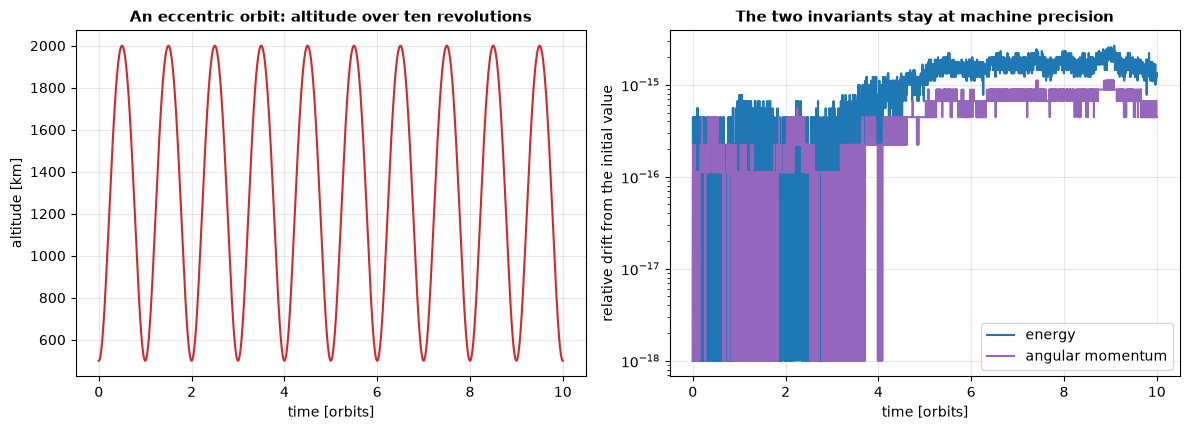

In [2]:
r_perigee = R_EARTH + 500.0
r_apogee = R_EARTH + 2000.0
a = 0.5 * (r_perigee + r_apogee)
e = (r_apogee - r_perigee) / (r_apogee + r_perigee)

orbit = ClassicalElements(
    a=a, e=e, i=np.deg2rad(51.6),
    raan=np.deg2rad(40.0), argp=np.deg2rad(30.0), mean_anomaly=0.0,
)
state0 = cartesian_state_from_elements(orbit, MU_EARTH)
period = 2 * np.pi * np.sqrt(a**3 / MU_EARTH)

t_eval = np.linspace(0.0, 10 * period, 4000)
sol = propagate(two_body_dynamics_symbolic(), state0, t_eval, pars=[MU_EARTH]).y

r = np.linalg.norm(sol[:3], axis=0)
v = np.linalg.norm(sol[3:], axis=0)
energy = 0.5 * v**2 - MU_EARTH / r
h = np.linalg.norm(np.cross(sol[:3].T, sol[3:].T), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(t_eval / period, r - R_EARTH, color=COL_NUM)
axes[0].set_xlabel("time [orbits]")
axes[0].set_ylabel("altitude [km]")
axes[0].set_title("An eccentric orbit: altitude over ten revolutions")

axes[1].semilogy(t_eval / period, np.abs(energy / energy[0] - 1) + 1e-18, color=COL_ANA, label="energy")
axes[1].semilogy(t_eval / period, np.abs(h / h[0] - 1) + 1e-18, color=COL_AUX, label="angular momentum")
axes[1].set_xlabel("time [orbits]")
axes[1].set_ylabel("relative drift from the initial value")
axes[1].set_title("The two invariants stay at machine precision")
axes[1].legend()

fig.tight_layout()

print(f"period: {period / 60:.2f} min, eccentricity: {e:.4f}")
print(f"largest relative energy error over ten orbits:           {np.max(np.abs(energy / energy[0] - 1)):.2e}")
print(f"largest relative angular momentum error over ten orbits: {np.max(np.abs(h / h[0] - 1)):.2e}")

Both invariants stay within a few units of machine precision over ten orbits, with no tuning of step size anywhere: heyoka picks order and step on its own. This is the accuracy every "truth" trajectory in this project inherits, and it is why the later notebooks can attribute any discrepancy they measure to the model under test, not to the integrator.

## Classical orbital elements

The six Cartesian numbers $[\mathbf r, \mathbf v]$ change at every instant, even on an orbit that never changes. The classical elements describe the same state as a size ($a$), a shape ($e$), an orientation ($i$, $\Omega$, $\omega$) and a position along the orbit ($M$): on a two-body orbit the first five are constant and only the mean anomaly advances, linearly, at the mean motion $n=\sqrt{\mu/a^3}$.

`classical_elements_from_state` and `cartesian_state_from_elements` convert in the two directions. The check below converts every propagated state back to elements. The five constant elements should not move, and the mean anomaly should grow as $n\,t$. The inverse conversion needs Kepler's equation, $M = E - e\sin E$, solved by Newton's method, so a round trip through both functions is also a check of that solver.

In [3]:
elements = [classical_elements_from_state(sol[:, k], MU_EARTH) for k in range(sol.shape[1])]

a_series = np.array([el.a for el in elements])
e_series = np.array([el.e for el in elements])
i_series = np.array([el.i for el in elements])
raan_series = np.array([el.raan for el in elements])
argp_series = np.array([el.argp for el in elements])
m_series = np.unwrap(np.array([el.mean_anomaly for el in elements]))

n = np.sqrt(MU_EARTH / a**3)

print("largest deviation of the constant elements along the propagation")
print(f"  a:    {np.max(np.abs(a_series - orbit.a)) * 1e3:.2e} m")
print(f"  e:    {np.max(np.abs(e_series - orbit.e)):.2e}")
print(f"  i:    {np.rad2deg(np.max(np.abs(i_series - orbit.i))):.2e} deg")
print(f"  raan: {np.rad2deg(np.max(np.abs(raan_series - orbit.raan))):.2e} deg")
print(f"  argp: {np.rad2deg(np.max(np.abs(argp_series - orbit.argp))):.2e} deg")
print(f"largest deviation of the mean anomaly from n*t: {np.rad2deg(np.max(np.abs(m_series - n * t_eval))):.2e} deg")

round_trip = cartesian_state_from_elements(classical_elements_from_state(state0, MU_EARTH), MU_EARTH)
print(f"state -> elements -> state round trip error: {np.linalg.norm(round_trip[:3] - state0[:3]) * 1e3:.2e} m")

largest deviation of the constant elements along the propagation
  a:    1.73e-08 m
  e:    1.79e-15
  i:    3.82e-14 deg
  raan: 3.82e-14 deg
  argp: 5.28e-13 deg
largest deviation of the mean anomaly from n*t: 2.37e-11 deg
state -> elements -> state round trip error: 5.48e-09 m


The difference between the mean anomaly and the true anomaly is what an eccentric orbit looks like in time: the spacecraft moves fast near perigee and slowly near apogee, so the true anomaly runs ahead of the mean anomaly on the way out and falls behind on the way back. The plot shows the same orbit in its own plane, sampled at equal time intervals, next to the two anomalies over one revolution.

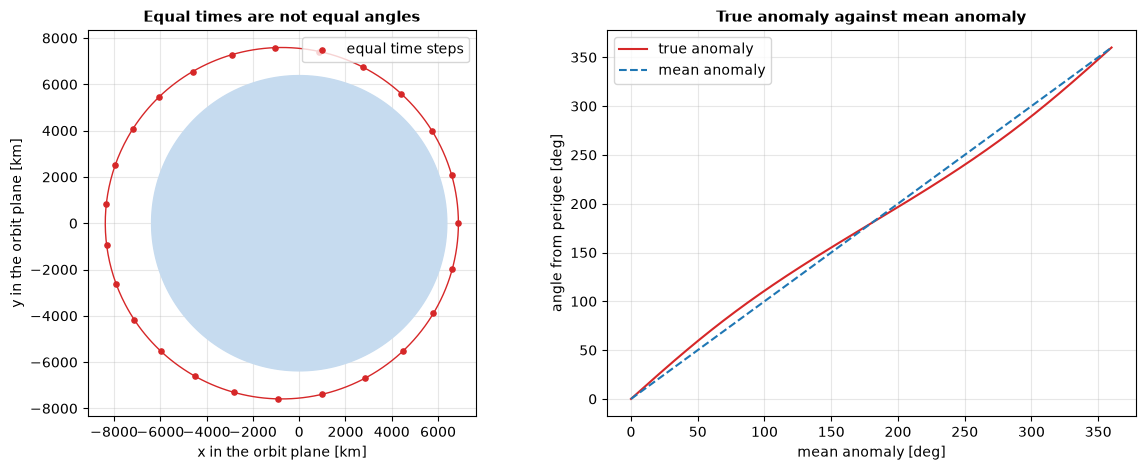

In [4]:
m_grid = np.linspace(0.0, 2 * np.pi, 400)
nu_grid = np.empty_like(m_grid)
xy = np.empty((2, len(m_grid)))
for k, m in enumerate(m_grid):
    el = ClassicalElements(a=a, e=e, i=0.0, raan=0.0, argp=0.0, mean_anomaly=m)
    s = cartesian_state_from_elements(el, MU_EARTH)
    xy[:, k] = s[:2]
    nu_grid[k] = np.arctan2(s[1], s[0]) % (2 * np.pi)
nu_grid[-1] = 2 * np.pi

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

theta = np.linspace(0, 2 * np.pi, 200)
axes[0].fill(R_EARTH * np.cos(theta), R_EARTH * np.sin(theta), color="#c6dbef", zorder=1)
axes[0].plot(xy[0], xy[1], color=COL_NUM, lw=1.0, zorder=2)
axes[0].scatter(xy[0, ::16], xy[1, ::16], s=14, color=COL_NUM, zorder=3, label="equal time steps")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x in the orbit plane [km]")
axes[0].set_ylabel("y in the orbit plane [km]")
axes[0].set_title("Equal times are not equal angles")
axes[0].legend(loc="upper right")

axes[1].plot(np.rad2deg(m_grid), np.rad2deg(nu_grid), color=COL_NUM, label="true anomaly")
axes[1].plot(np.rad2deg(m_grid), np.rad2deg(m_grid), color=COL_ANA, ls="--", label="mean anomaly")
axes[1].set_xlabel("mean anomaly [deg]")
axes[1].set_ylabel("angle from perigee [deg]")
axes[1].set_title("True anomaly against mean anomaly")
axes[1].legend()

fig.tight_layout()

## J2: the orbit plane and the perigee drift

The Earth is not a point mass. Its equatorial bulge, described by the $J_2$ coefficient, adds a small acceleration that depends on latitude. Over one orbit its effect on $a$, $e$ and $i$ averages out, but it leaves a net drift in the three angles: the ascending node moves along the equator, the perigee rotates within the orbit plane, and the mean anomaly advances at a slightly different rate. `j2_secular_rates` gives these three averaged rates in closed form.

The check uses a 500 km orbit at 51.6 degrees, the reference orbit of the rendezvous mission in the later notebooks, with a small eccentricity so that the perigee is well defined. `two_body_j2_dynamics_symbolic` is propagated for three days and sampled once per revolution, always at the same point of the orbit, so that the short-period oscillations cancel and only the secular drift is left to compare against the formula.

nodal rate:   formula -4.7533 deg/day, numerical -4.7647 deg/day
apsidal rate: formula +3.5550 deg/day, numerical +3.5667 deg/day


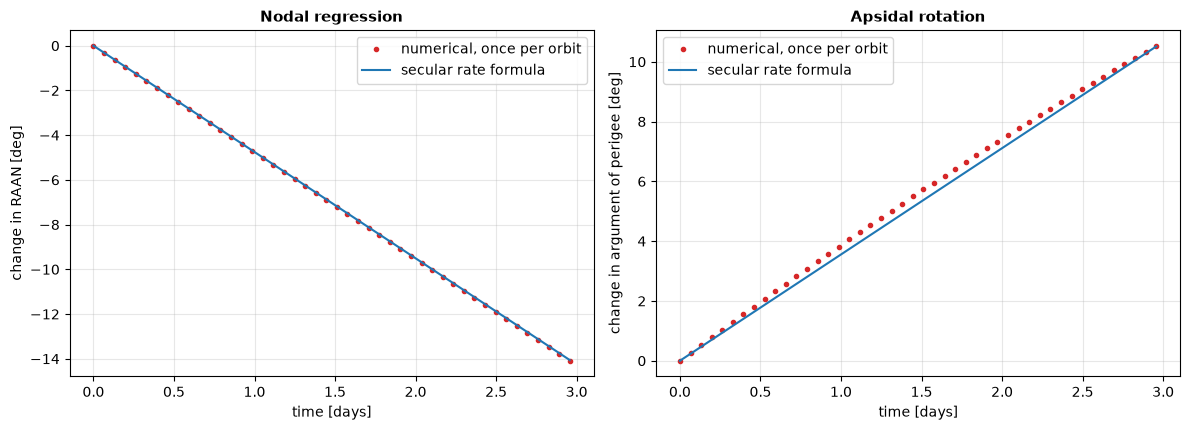

In [5]:
a_j2 = R_EARTH + 500.0
e_j2 = 0.01
i_j2 = np.deg2rad(51.6)
orbit_j2 = ClassicalElements(a=a_j2, e=e_j2, i=i_j2, raan=np.deg2rad(40.0), argp=np.deg2rad(30.0), mean_anomaly=0.0)
state_j2 = cartesian_state_from_elements(orbit_j2, MU_EARTH)
period_j2 = 2 * np.pi * np.sqrt(a_j2**3 / MU_EARTH)

n_rev = int(3 * 86400 / period_j2)
t_rev = np.arange(n_rev + 1) * period_j2
sol_j2 = propagate(
    two_body_j2_dynamics_symbolic(), state_j2, t_rev,
    pars=[MU_EARTH, J2_EARTH, R_EARTH],
).y

el_j2 = [classical_elements_from_state(sol_j2[:, k], MU_EARTH) for k in range(sol_j2.shape[1])]
raan_num = np.unwrap(np.array([el.raan for el in el_j2]))
argp_num = np.unwrap(np.array([el.argp for el in el_j2]))

raan_dot, argp_dot, _ = j2_secular_rates(a_j2, e_j2, i_j2, MU_EARTH, J2_EARTH, R_EARTH)

days = t_rev / 86400.0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(days, np.rad2deg(raan_num - raan_num[0]), "o", ms=3, color=COL_NUM, label="numerical, once per orbit")
axes[0].plot(days, np.rad2deg(raan_dot * t_rev), color=COL_ANA, label="secular rate formula")
axes[0].set_xlabel("time [days]")
axes[0].set_ylabel("change in RAAN [deg]")
axes[0].set_title("Nodal regression")
axes[0].legend()

axes[1].plot(days, np.rad2deg(argp_num - argp_num[0]), "o", ms=3, color=COL_NUM, label="numerical, once per orbit")
axes[1].plot(days, np.rad2deg(argp_dot * t_rev), color=COL_ANA, label="secular rate formula")
axes[1].set_xlabel("time [days]")
axes[1].set_ylabel("change in argument of perigee [deg]")
axes[1].set_title("Apsidal rotation")
axes[1].legend()

fig.tight_layout()

raan_fit = np.polyfit(t_rev, raan_num, 1)[0]
argp_fit = np.polyfit(t_rev, argp_num, 1)[0]
print(f"nodal rate:   formula {np.rad2deg(raan_dot) * 86400:+.4f} deg/day, numerical {np.rad2deg(raan_fit) * 86400:+.4f} deg/day")
print(f"apsidal rate: formula {np.rad2deg(argp_dot) * 86400:+.4f} deg/day, numerical {np.rad2deg(argp_fit) * 86400:+.4f} deg/day")

The node regresses by about five degrees per day and the perigee rotates forward by about three and a half, and on both rates the formula and the nonlinear propagation agree to a fraction of a percent. The perigee points bow slightly away from the straight line and come back to it: the formula is a first-order average, while the elements extracted from a single Cartesian state are osculating elements, and for a nearly circular orbit the osculating perigee carries a slow periodic wobble on top of the drift. The secular trend is the same, and it is the trend that matters downstream.

These two drifts come back twice in this project. The relative orbit elements under J2 are built on the fact that two spacecraft with slightly different $a$, $e$ or $i$ drift at slightly different rates, and the illumination analysis depends on the nodal regression, because it is what slowly turns the orbit plane with respect to the Sun.

One classical use of the nodal drift is worth showing before moving on. Choosing the inclination so that the node advances by exactly one revolution per year keeps the orbit plane fixed with respect to the Sun. `sun_synchronous_inclination` solves for that inclination, which is always slightly retrograde.

sun-synchronous inclination at 500 km: 97.40 deg
sun-synchronous inclination at 800 km: 98.60 deg


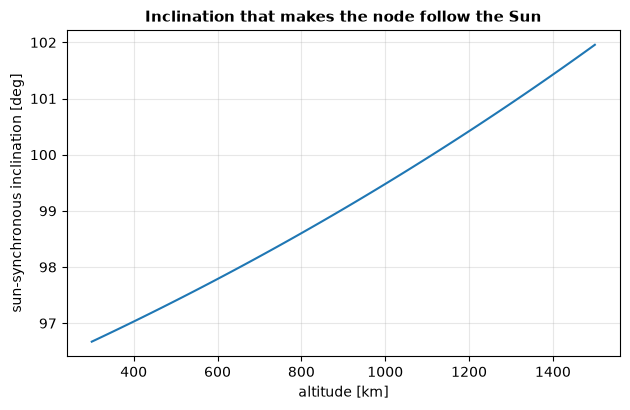

In [6]:
altitudes = np.linspace(300.0, 1500.0, 100)
incl_sso = [np.rad2deg(sun_synchronous_inclination(R_EARTH + h, 0.0, MU_EARTH, J2_EARTH, R_EARTH)) for h in altitudes]

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(altitudes, incl_sso, color=COL_ANA)
ax.set_xlabel("altitude [km]")
ax.set_ylabel("sun-synchronous inclination [deg]")
ax.set_title("Inclination that makes the node follow the Sun")
fig.tight_layout()

print(f"sun-synchronous inclination at 500 km: {np.rad2deg(sun_synchronous_inclination(R_EARTH + 500.0, 0.0, MU_EARTH, J2_EARTH, R_EARTH)):.2f} deg")
print(f"sun-synchronous inclination at 800 km: {np.rad2deg(sun_synchronous_inclination(R_EARTH + 800.0, 0.0, MU_EARTH, J2_EARTH, R_EARTH)):.2f} deg")

## Drag: the orbit decays

J2 moves the orbit around without changing its energy. Atmospheric drag is the one perturbation here that removes energy, and it does so continuously: the spacecraft loses altitude, and, counterintuitively, speeds up as it does, because a lower orbit is a faster one.

`two_body_drag_dynamics_symbolic` adds a drag acceleration opposing the velocity relative to the rotating atmosphere, with an exponential density model. For a circular orbit, equating the power removed by drag to the rate of change of orbital energy gives a closed form for the decay rate, $\dot a = -\rho\,\frac{C_dA}{m}\sqrt{\mu a}$, which is what `circular_orbit_decay_rate` returns. The check propagates a 400 km circular orbit for ten days and compares it with that formula, integrated in time with the density updated as the orbit sinks. The density values are representative of moderate solar activity and are meant to size the effect, not to forecast it.

altitude lost in ten days: numerical (atmosphere at rest) 2506.2 m, formula 2506.2 m
with the atmosphere rotating with the Earth:              2187.8 m
initial decay rate from the formula: -245.4 m/day


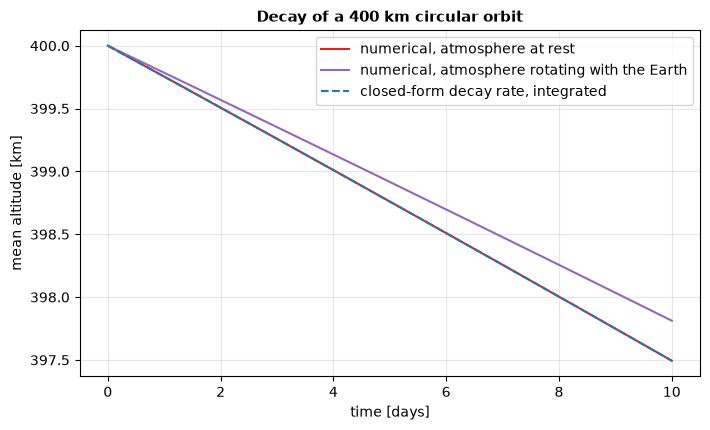

In [7]:
alt0 = 400.0
a0 = R_EARTH + alt0
rho0, scale_height = 3.725e-12, 58.515   # kg/m^3 and km at the 400 km reference
bc = 2.2 * 1.0 / 150.0                    # Cd * A / m for a 150 kg spacecraft with 1 m^2 of frontal area

v0 = np.sqrt(MU_EARTH / a0)
state_drag = np.array([a0, 0.0, 0.0, 0.0, v0, 0.0])
t_drag = np.linspace(0.0, 10 * 86400.0, 2000)


def semi_major_axis(states):
    radius = np.linalg.norm(states[:3], axis=0)
    speed = np.linalg.norm(states[3:6], axis=0)
    return -MU_EARTH / (2 * (0.5 * speed**2 - MU_EARTH / radius))


a_fixed_atmosphere = semi_major_axis(propagate(
    two_body_drag_dynamics_symbolic(), state_drag, t_drag,
    pars=[MU_EARTH, bc, rho0, a0, scale_height, 0.0],
).y)
a_rotating_atmosphere = semi_major_axis(propagate(
    two_body_drag_dynamics_symbolic(), state_drag, t_drag,
    pars=[MU_EARTH, bc, rho0, a0, scale_height, OMEGA_EARTH],
).y)

# integrate the closed-form decay rate with a simple fixed-step scheme
a_formula = np.empty_like(t_drag)
a_formula[0] = a0
for k in range(len(t_drag) - 1):
    rho = rho0 * np.exp(-(a_formula[k] - a0) / scale_height)
    a_formula[k + 1] = a_formula[k] + circular_orbit_decay_rate(a_formula[k], bc, rho, MU_EARTH) * (t_drag[k + 1] - t_drag[k])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(t_drag / 86400, a_fixed_atmosphere - R_EARTH, color=COL_NUM, label="numerical, atmosphere at rest")
ax.plot(t_drag / 86400, a_rotating_atmosphere - R_EARTH, color=COL_AUX, label="numerical, atmosphere rotating with the Earth")
ax.plot(t_drag / 86400, a_formula - R_EARTH, color=COL_ANA, ls="--", label="closed-form decay rate, integrated")
ax.set_xlabel("time [days]")
ax.set_ylabel("mean altitude [km]")
ax.set_title("Decay of a 400 km circular orbit")
ax.legend()
fig.tight_layout()

print(f"altitude lost in ten days: numerical (atmosphere at rest) {(a0 - a_fixed_atmosphere[-1]) * 1e3:.1f} m, "
      f"formula {(a0 - a_formula[-1]) * 1e3:.1f} m")
print(f"with the atmosphere rotating with the Earth:              {(a0 - a_rotating_atmosphere[-1]) * 1e3:.1f} m")
print(f"initial decay rate from the formula: {circular_orbit_decay_rate(a0, bc, rho0, MU_EARTH) * 1e3 * 86400:.1f} m/day")

With the atmosphere held at rest, the propagation and the integrated formula agree closely, which validates the drag model against an independent energy argument. Letting the atmosphere rotate with the Earth lowers the relative speed on this equatorial, prograde orbit and slows the decay by a little over ten percent, which is the correction the formula deliberately leaves out.

The decay rate is proportional to the ballistic coefficient $C_dA/m$. Two spacecraft with different ballistic coefficients therefore decay at different rates, and that difference is what the differential drag notebook later turns into a way of controlling along-track separation without propellant.

## Summary

A single spacecraft around the Earth is described by the two-body problem, whose energy and angular momentum the heyoka integration preserves to machine precision, and whose solution is most readable in classical elements: five constants and one angle that advances at the mean motion. J2 leaves the size and shape of the orbit alone and makes its node and perigee drift at rates that `j2_secular_rates` predicts and the nonlinear propagation confirms. Drag removes energy and makes the orbit decay at a rate that `circular_orbit_decay_rate` predicts from the ballistic coefficient and the local density.

The next notebook, `cw_fundamentals.ipynb`, puts a second spacecraft on a nearby orbit and asks how it moves as seen from the first one. That question is the core of every rendezvous.